In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/arjunbhasin2013/ccdata/CC GENERAL.csv


# Credit Card Customer Segmentation – Muthoot Prep

**Dataset to attach:** [Credit Card Dataset for Clustering](https://www.kaggle.com/datasets/arjunbhasin2013/ccdata) (`arjunbhasin2013/ccdata`). The file used is `CC GENERAL.csv`.

**Before you run:** turn **Internet** on in the Kaggle editor (Settings panel on the right). The notebook installs MLflow. If the Internet switch is greyed out, verify your phone number in Kaggle account settings first, then click **Save & Run All**.

## Step 1: Problem Statement
- **Problem type (of the 6):** Segmentation – credit-card customer clustering
- **JD link:** Matches "clustering" and names Scikit-learn. JD-based.
- **Business problem:** Group credit-card customers by spending, cash-advance and repayment behaviour, so product, credit and collections teams can set offers, credit limits and risk actions by segment instead of treating every customer the same.
- **Who uses it:** The product / credit-limit team, and collections, when they design segment-based offers or review limits and early-warning lists.
- **Target:** There is no default or take-up label. Each customer is assigned to a cluster, and we name the clusters from their mean behaviour.
- **Learning type:** Unsupervised clustering with K-Means. The model does not predict a yes/no outcome; it finds groups in the feature space, and we interpret those groups for the business.

**Interview line**
- "I framed this as an unsupervised segmentation problem: cluster credit-card customers by spending, cash-advance and repayment behaviour, then give each group a business name the credit and product teams can act on." 

## Roadmap
**What we do**
- Follow 12 steps from the business problem to a saved, tracked segmentation model.

**Flow:** Problem → Load → Missing values → EDA → Log transform → Scale → Choose k → K-Means → Profile and name segments → PCA plot → Business actions → MLflow → Save model

**Libraries flow:** Problem → Load (pandas) → Missing values (pandas median) → EDA (pandas, matplotlib, skewness and correlation) → Log transform (numpy log1p) → Scale (scikit-learn StandardScaler) → Choose k (scikit-learn KMeans, silhouette_score, matplotlib) → K-Means (scikit-learn KMeans) → Profile and name segments (pandas) → PCA plot (scikit-learn PCA, matplotlib) → Business actions (pandas) → MLflow (mlflow) → Save model (joblib)

**Steps**
- Step 1: Problem statement, load the data and inspect it
- Step 2: Fill missing values with the median
- Step 3: EDA – skewness, distributions and correlation
- Step 4: Log-transform the skewed amount and count columns
- Step 5: Scale the features with StandardScaler
- Step 6: Choose k with the elbow method (inertia) and the silhouette score
- Step 7: Fit K-Means
- Step 8: Profile each cluster and give it a business name
- Step 9: PCA 2D plot of the clusters
- Step 10: Business actions per segment
- Step 11: Log the parameters and the silhouette score to MLflow
- Step 12: Save the scaler and the model with joblib

**Why it matters**
- Shows the full ML lifecycle in order, which is what the JD asks for (JD-based).
- Easy to walk an interviewer through, one step at a time.

## Glossary
- **Segmentation / clustering:** grouping customers who behave in a similar way, without a yes/no label. The output is a segment name, not a probability.
- **K-Means:** an algorithm that places k centres in the feature space and assigns each customer to the nearest centre. It uses Euclidean distance, so scale matters.
- **Inertia:** the total squared distance from each customer to their cluster centre. Lower is tighter, but inertia always falls as k rises, so we look for an elbow rather than the lowest number.
- **Elbow method:** a plot of inertia against k. We look for the k where the drop in inertia starts to flatten, then check whether those groups are easy to name.
- **Silhouette score:** a score from -1 to 1 that compares how close a point is to its own cluster versus the next-nearest cluster. Higher means clearer separation. In behavioural card data, values around 0.2 are common and still usable if the mean profiles are distinct.
- **StandardScaler:** puts each feature on mean 0 and standard deviation 1, so credit limit in thousands does not dominate a 0-1 frequency when we compute distances.
- **log1p:** log(1 + x). Used on right-skewed amounts and counts that include zeros (a customer with no cash advance would be undefined under a plain log).
- **Skewness:** a measure of whether a distribution has a long tail on one side. Spend and balance columns in this file are right-skewed: most customers sit at lower amounts, and a few are very large.
- **Pearson correlation:** a measure of linear association between two numeric features, from -1 to 1. Purchases and one-off purchases are highly correlated in this file.
- **PCA (2D plot):** a rotation of the features into a small number of components, used here only to draw the clusters. The K-Means fit itself is done in the full scaled feature space.
- **Transactors:** customers who purchase regularly and pay down more of the balance, with little cash-advance use. Usually the lower-risk, rewards-friendly segment.
- **Revolvers:** customers who keep a high balance and a high spend, and only sometimes pay in full. Interest income is higher, and so is credit risk.
- **Cash-advance users:** customers who take large cash advances, buy little on the card, and almost never pay in full. A high-risk behavioural group.
- **Low-activity customers:** customers with low balances, low spend and low cash-advance use, and a balance that is updated less often. A target for activation, or for reviewing unused limits.
- **CREDIT_LIMIT strategy:** setting or reviewing how much credit to extend, by segment rather than with one rule for the whole book.
- **CUST_ID:** the customer key. It is not a behavioural feature, so it is kept for joining the segment back to the customer, and dropped before clustering.
- **PRC_FULL_PAYMENT:** the share of months in which the customer paid the balance in full.
- **TENURE:** months as a card customer in this file, from 6 to 12. Most customers sit at 12 months.
- **Median imputation:** filling a missing numeric value with the middle value of that column. Preferable here to the mean, because minimum payments are heavily right-skewed.

### Load data and inspect it
**What we do**
- Load the customer table (one row per credit-card holder). The CSV is comma-separated.
- Check rows, columns, data types, missing values, exact duplicate rows and unique customer IDs.
- `CUST_ID` is the customer key, not a behavioural feature, so we will drop it later before clustering and keep it only to map the segment back to the customer.

**Why it matters**
- Confirms the file loaded correctly and that we know the path.
- Missing values and duplicates are the first data-quality checks. Duplicate rows would give the same customer twice as much weight in K-Means.
- A unique ID count that matches the row count means we are clustering customers, not repeated snapshots of the same person.

**Domain link**
- Each row is one card holder, with about six months of balance, purchase, cash-advance and payment behaviour, plus a credit limit and tenure.
- The same kind of customer-level table would be used to build segments for offers, ticket size and risk.
- An NBFC like Muthoot would hold a similar table for gold-loan, deposit or insurance behaviour.
- JD-based: "data collection" and "data preparation" in the ML lifecycle. Domain-based: customer-level card behaviour.

**Interview line**
- "First I loaded the customer-level file, checked the row count against unique customer IDs, and noted the missing values in credit limit and minimum payments before doing any clustering." 

In [2]:
path = '/kaggle/input/datasets/arjunbhasin2013/ccdata/CC GENERAL.csv'
df = pd.read_csv(path)

print(f"Rows     : {df.shape[0]:,}")
print(f"Columns  : {df.shape[1]}")
print(f"Column names: {list(df.columns)}")
print("\nData types:")
print(df.dtypes)
print("\nFirst 5 rows:")
print(df.head())

print(f"\nMissing values (Pandas nulls): {df.isna().sum().sum():,}")
print(f"Duplicate rows               : {df.duplicated().sum():,}")
print(f"Unique customer IDs          : {df['CUST_ID'].nunique():,}")

Rows     : 8,950
Columns  : 18
Column names: ['CUST_ID', 'BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']

Data types:
CUST_ID                                 str
BALANCE                             float64
BALANCE_FREQUENCY                   float64
PURCHASES                           float64
ONEOFF_PURCHASES                    float64
INSTALLMENTS_PURCHASES              float64
CASH_ADVANCE                        float64
PURCHASES_FREQUENCY                 float64
ONEOFF_PURCHASES_FREQUENCY          float64
PURCHASES_INSTALLMENTS_FREQUENCY    float64
CASH_ADVANCE_FREQUENCY              float64
CASH_ADVANCE_TRX                      int64
PURCHASES_TRX                         int64
CREDIT_LIMIT         

**Findings**
- The file has 8,950 rows and 18 columns. There are 8,950 unique customer IDs and no exact duplicate rows.
- There are 314 missing values: 1 in `CREDIT_LIMIT` and 313 in `MINIMUM_PAYMENTS` (3.50%).
- **How to read this:** one row should be one customer. If the unique ID count matches the row count, we can cluster the book as it stands.

## Step 2: Missing Values (median fill)
**What we do**
- Print the missing-value count for every column that has a gap.
- Fill those numeric gaps with the column median.

**Why it matters**
- K-Means cannot be fitted on rows that contain a missing value, and dropping those rows would throw away customers (most of the gaps are in `MINIMUM_PAYMENTS`).
- The median is a better fill than the mean here, because minimum payments are heavily right-skewed: a few very large values would pull the mean up, and we would be filling typical customers with an unusually high number.

**Domain link**
- A missing minimum payment can mean the customer has not yet been billed, or that the field was not captured. Filling with the median is a simple, conservative choice so those customers can still be segmented.
- At an NBFC, the same rule would apply to a missing sanctioned amount or outstanding balance: use a robust fill, and later check whether "missing" itself is a useful flag.
- JD-based: "data preparation". Domain-based: keeping the full customer book in the segmentation.

**Interview line**
- "I filled credit limit and minimum payments with the median rather than the mean, because minimum payments are heavily right-skewed and I did not want a few large values to set the fill." 

In [3]:
print("Missing values by column:")
missing = df.isna().sum()
for col, n in missing.items():
    if n > 0:
        print(f"  {col:20s}  {n:,}  ({n / len(df):.2%})")
print(f"\nTotal missing values: {missing.sum():,}")

# Median is robust to the long right tail in minimum payments
for col in df.columns:
    n = df[col].isna().sum()
    if n > 0:
        median = df[col].median()
        df[col] = df[col].fillna(median)
        print(f"Filled {col} with median {median:,.2f}  ({n:,} rows)")

print(f"\nMissing values after the fill: {df.isna().sum().sum():,}")

Missing values by column:
  CREDIT_LIMIT          1  (0.01%)
  MINIMUM_PAYMENTS      313  (3.50%)

Total missing values: 314
Filled CREDIT_LIMIT with median 3,000.00  (1 rows)
Filled MINIMUM_PAYMENTS with median 312.34  (313 rows)

Missing values after the fill: 0


**Findings**
- `CREDIT_LIMIT` had 1 missing row and was filled with the median 3,000.00. `MINIMUM_PAYMENTS` had 313 missing rows (3.50%) and was filled with the median 312.34.
- Missing values are 0 after the fill. No customer was dropped.
- **How to read this:** no customer was dropped. The fill is a practical choice so K-Means can run on the full book.

## Step 3: Exploratory Data Analysis (EDA)
**What we do**
- Print a short summary (mean, median, min, max) and the skewness of every numeric column.
- Plot distributions for the main business amounts: balance, purchases, cash advance, credit limit, payments and the share of months paid in full.
- Print the strongest feature pairs by Pearson correlation, and draw a correlation heatmap.

**Why it matters**
- Skewness tells us which columns have a long right tail. K-Means uses Euclidean distance, so a few very large spenders would otherwise pull the centres toward themselves. That is why the next step logs those columns.
- Correlation shows which features move together (for example purchases and one-off purchases). K-Means does not need us to drop correlated columns the way a linear model does, but we should know that some dimensions are telling a similar story.
- The histograms are the picture we will later compare with the cluster means.

**Stats used:** skewness, Pearson correlation.

**Domain link**
- Balance, purchases, cash advances, credit limit and the share of full payments are the levers that drive offers, limits and risk: high cash-advance use is a risk flag, a high full-payment rate is a lower-risk flag, and unused limit is capital that is earning little.
- An NBFC like Muthoot would read the same kinds of signal on gold-loan outstanding, ticket size or repayment regularity.
- JD-based: "exploratory analysis" and "statistical analysis". Domain-based: card-behaviour patterns that drive offers, limits and risk.

**Interview line**
- "I checked skewness and correlations before clustering: spend and balance are right-skewed, so I planned a log transform, and purchases are highly correlated with one-off purchases, which I noted rather than dropping." 

Numeric summary (mean, median, min, max):
  BALANCE                              mean =   1,564.47  |  median =     873.39  |  min =       0.00  |  max =  19,043.14
  BALANCE_FREQUENCY                    mean =       0.88  |  median =       1.00  |  min =       0.00  |  max =       1.00
  PURCHASES                            mean =   1,003.20  |  median =     361.28  |  min =       0.00  |  max =  49,039.57
  ONEOFF_PURCHASES                     mean =     592.44  |  median =      38.00  |  min =       0.00  |  max =  40,761.25
  INSTALLMENTS_PURCHASES               mean =     411.07  |  median =      89.00  |  min =       0.00  |  max =  22,500.00
  CASH_ADVANCE                         mean =     978.87  |  median =       0.00  |  min =       0.00  |  max =  47,137.21
  PURCHASES_FREQUENCY                  mean =       0.49  |  median =       0.50  |  min =       0.00  |  max =       1.00
  ONEOFF_PURCHASES_FREQUENCY           mean =       0.20  |  median =       0.08  |  min =       

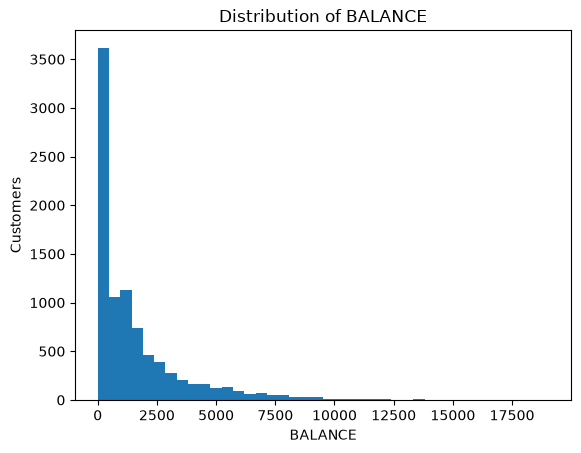

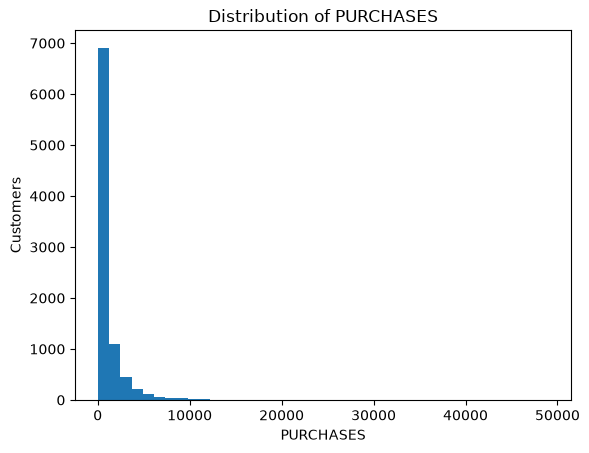

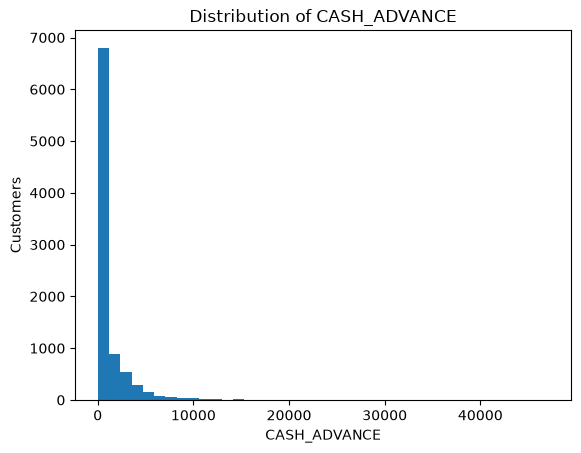

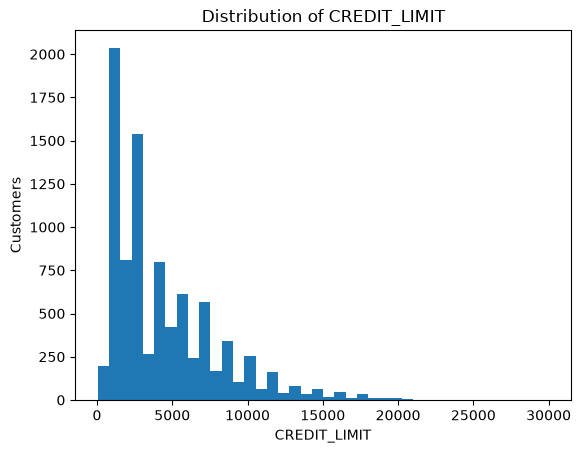

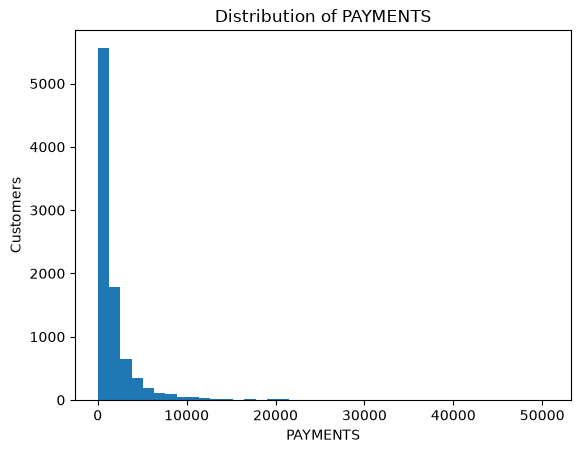

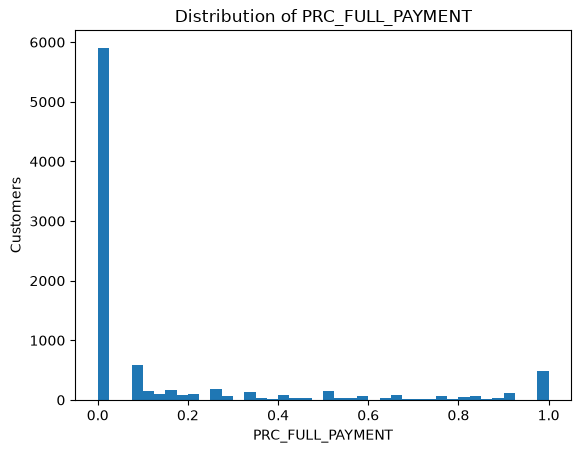


Strongest feature pairs (|correlation| >= 0.50):
  PURCHASES                            ONEOFF_PURCHASES                     r =  0.917
  PURCHASES_FREQUENCY                  PURCHASES_INSTALLMENTS_FREQUENCY     r =  0.863
  CASH_ADVANCE_FREQUENCY               CASH_ADVANCE_TRX                     r =  0.800
  PURCHASES                            PURCHASES_TRX                        r =  0.690
  PURCHASES                            INSTALLMENTS_PURCHASES               r =  0.680
  CASH_ADVANCE                         CASH_ADVANCE_TRX                     r =  0.656
  CASH_ADVANCE                         CASH_ADVANCE_FREQUENCY               r =  0.629
  INSTALLMENTS_PURCHASES               PURCHASES_TRX                        r =  0.628
  PURCHASES                            PAYMENTS                             r =  0.603
  PURCHASES_FREQUENCY                  PURCHASES_TRX                        r =  0.568
  ONEOFF_PURCHASES                     PAYMENTS                             r = 

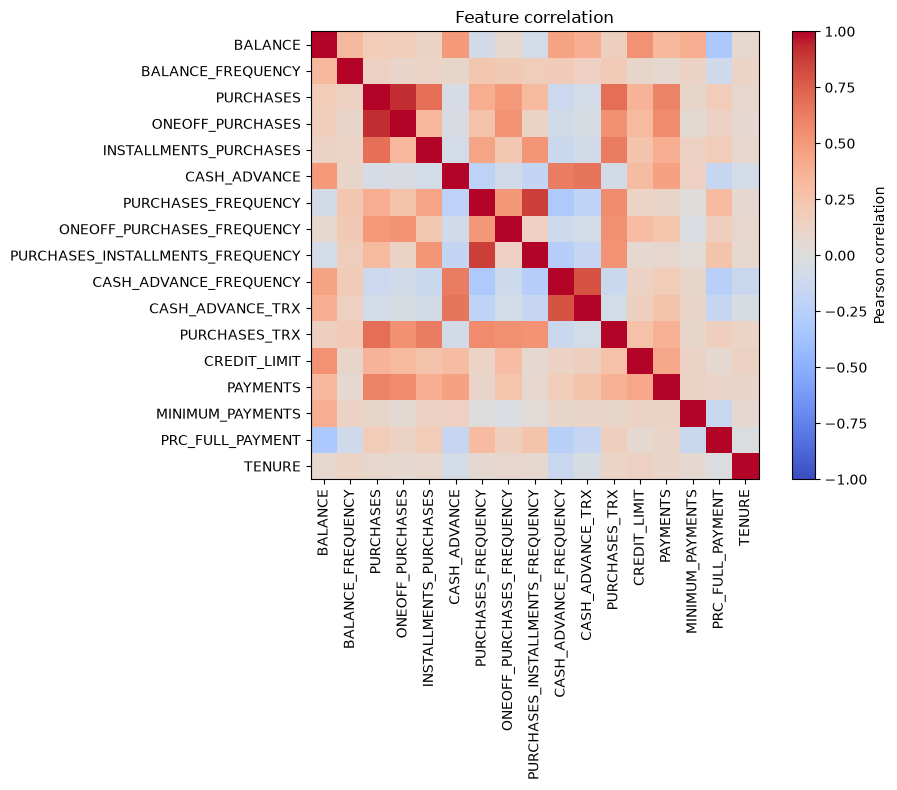

In [4]:
import matplotlib.pyplot as plt

# CUST_ID is the key, not a feature
numeric_cols = [c for c in df.columns if c != 'CUST_ID']

print("Numeric summary (mean, median, min, max):")
for col in numeric_cols:
    s = df[col]
    print(
        f"  {col:35s}  mean = {s.mean():10,.2f}  |  "
        f"median = {s.median():10,.2f}  |  min = {s.min():10,.2f}  |  max = {s.max():10,.2f}"
    )

print("\nSkewness (positive = right tail):")
skew = df[numeric_cols].skew().sort_values(ascending=False)
print(skew.to_string())

# A few charts of the main business amounts
for col in ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS', 'PRC_FULL_PAYMENT']:
    plt.hist(df[col], bins=40)
    plt.xlabel(col)
    plt.ylabel('Customers')
    plt.title(f'Distribution of {col}')
    plt.show()

corr = df[numeric_cols].corr()
print("\nStrongest feature pairs (|correlation| >= 0.50):")
pairs = []
for i, c1 in enumerate(numeric_cols):
    for c2 in numeric_cols[i + 1:]:
        r = corr.loc[c1, c2]
        if abs(r) >= 0.50:
            pairs.append((abs(r), r, c1, c2))
pairs.sort(reverse=True)
for _, r, c1, c2 in pairs:
    print(f"  {c1:35s}  {c2:35s}  r = {r:6.3f}")

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Pearson correlation')
plt.xticks(range(len(numeric_cols)), numeric_cols, rotation=90)
plt.yticks(range(len(numeric_cols)), numeric_cols)
plt.title('Feature correlation')
plt.tight_layout()
plt.show()

**Findings**
- The most right-skewed columns are `MINIMUM_PAYMENTS` (13.85), `ONEOFF_PURCHASES` (10.05), `PURCHASES` (8.14), `INSTALLMENTS_PURCHASES` (7.30), `PAYMENTS` (5.91), `CASH_ADVANCE_TRX` (5.72) and `CASH_ADVANCE` (5.17). `TENURE` (-2.94) and `BALANCE_FREQUENCY` (-2.02) are left-skewed: most customers sit at tenure 12 and a balance frequency of 1.
- The histograms show the typical customer well below the mean: balance median 873 vs mean 1,564 (max 19,043); purchases median 361 vs mean 1,003 (max 49,040); cash advance median 0 vs mean 979 (max 47,137). A few very large values create the long right tail.
- The strongest correlations are `PURCHASES` with `ONEOFF_PURCHASES` (r = 0.917), `PURCHASES_FREQUENCY` with `PURCHASES_INSTALLMENTS_FREQUENCY` (r = 0.863), and `CASH_ADVANCE_FREQUENCY` with `CASH_ADVANCE_TRX` (r = 0.800).
- **How to read this:** a high skew means a long tail, not an error. A high correlation means two columns carry similar information; we keep both and remember that when we read the cluster profile.

## Step 4: Log-transform the Skewed Columns
**What we do**
- Keep a copy of the features in original units (`X_raw`), which we will use later to profile the clusters in rupees and rates the business can read.
- Apply `log1p` (that is, log(1 + x)) to the amount and count columns whose skewness is above 1. Frequency rates that already sit near 0-1 are left as they are.

**Why it matters**
- K-Means is pulled toward extreme values. Logging compresses the long right tail so a few very large spenders do not set the centres on their own.
- `log1p` is used because many customers have zero purchases or zero cash advances, and log(0) is not defined.
- We profile the clusters later on the original scale, so the business still sees mean balance and mean purchases in the original units, not in log units.

**Stats used:** skewness (before and after the transform).

**Domain link**
- Card spend, cash advances and outstanding balances are naturally skewed: most customers are modest, and a small group is very large.
- The same pattern appears in gold-loan outstanding or ticket size at an NBFC like Muthoot.
- JD-based: "data preparation" and "feature engineering". Domain-based: handling typical heavy-tailed financial amounts.

**Interview line**
- "I logged the right-skewed amount and count columns with log1p, because of zeros, and I kept a copy in original units so the cluster profile could still be read in rupees and rates." 

In [5]:
# Original units are kept for the business profile in Step 8
feature_cols = [c for c in df.columns if c != 'CUST_ID']
X_raw = df[feature_cols].copy()
X = X_raw.copy()

# Amount and count columns with a long right tail (skew > 1 and values above a 0-1 rate)
skewed_cols = [c for c in feature_cols if X[c].skew() > 1 and X[c].max() > 2]
print("Columns we log-transform (skew > 1, not a 0-1 rate):")
for col in skewed_cols:
    print(f"  {col:35s}  skew = {X[col].skew():6.2f}")

print("\nSkewness before log1p:")
print(X[skewed_cols].skew().sort_values(ascending=False).to_string())

for col in skewed_cols:
    X[col] = np.log1p(X[col])

print("\nSkewness after log1p:")
print(X[skewed_cols].skew().sort_values(ascending=False).to_string())
print(f"\nFeature matrix for clustering: {X.shape[0]:,} rows x {X.shape[1]} columns")

Columns we log-transform (skew > 1, not a 0-1 rate):
  BALANCE                              skew =   2.39
  PURCHASES                            skew =   8.14
  ONEOFF_PURCHASES                     skew =  10.05
  INSTALLMENTS_PURCHASES               skew =   7.30
  CASH_ADVANCE                         skew =   5.17
  CASH_ADVANCE_TRX                     skew =   5.72
  PURCHASES_TRX                        skew =   4.63
  CREDIT_LIMIT                         skew =   1.52
  PAYMENTS                             skew =   5.91
  MINIMUM_PAYMENTS                     skew =  13.85

Skewness before log1p:
MINIMUM_PAYMENTS          13.852446
ONEOFF_PURCHASES          10.045083
PURCHASES                  8.144269
INSTALLMENTS_PURCHASES     7.299120
PAYMENTS                   5.907620
CASH_ADVANCE_TRX           5.721298
CASH_ADVANCE               5.166609
PURCHASES_TRX              4.630655
BALANCE                    2.393386
CREDIT_LIMIT               1.522636

Skewness after log1p:
CASH_ADVAN

**Findings**
- Ten amount and count columns were logged with `log1p`. Skew before and after: `MINIMUM_PAYMENTS` 13.85 to 0.27, `ONEOFF_PURCHASES` 10.05 to 0.19, `PURCHASES` 8.14 to -0.76, `INSTALLMENTS_PURCHASES` 7.30 to -0.02, `PAYMENTS` 5.91 to -1.78, `CASH_ADVANCE_TRX` 5.72 to 0.94, `CASH_ADVANCE` 5.17 to 0.26, `PURCHASES_TRX` 4.63 to 0.03, `BALANCE` 2.39 to -0.86 and `CREDIT_LIMIT` 1.52 to -0.10.
- Frequency rates were left as they are. The feature matrix is 8,950 rows by 17 columns.
- **How to read this:** a lower skew after log1p means the long tail has been compressed. The cluster names will still be based on original-unit means, not on these log values.

## Step 5: StandardScaler
**What we do**
- Fit `StandardScaler` on the log-transformed feature matrix and transform it, so every feature has mean 0 and standard deviation 1.

**Why it matters**
- K-Means uses Euclidean distance. Without scaling, a credit limit of several thousand would dominate a purchase frequency that only runs from 0 to 1, and the clusters would mostly follow the largest-unit features.
- After scaling, a one-standard-deviation difference in limit and a one-standard-deviation difference in frequency count the same.

**Domain link**
- Card data always mixes rupee amounts, 0-1 rates and transaction counts. Scaling is what lets those different kinds of signal sit in the same distance calculation.
- The same issue appears if an NBFC clustered gold-loan outstanding (in rupees) together with renewal frequency or days past due.
- That mixing of amounts and rates is exactly what an NBFC like Muthoot would face on a gold-loan book.
- JD-based: "data preparation" and Scikit-learn. Domain-based: mixing amounts, rates and counts in one model.

**Interview line**
- "I scaled every feature after the log transform, because K-Means uses Euclidean distance and I did not want credit limit in thousands to dominate a 0-1 frequency." 

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Scaled matrix shape: {X_scaled.shape}")
print(f"Mean of scaled features (should be about 0): {X_scaled.mean():.4f}")
print(f"Std of scaled features  (should be about 1): {X_scaled.std():.4f}")
print("\nPer-feature mean and std after scaling:")
for name, mu, sd in zip(X.columns, X_scaled.mean(axis=0), X_scaled.std(axis=0)):
    print(f"  {name:35s}  mean = {mu:8.4f}  |  std = {sd:8.4f}")

Scaled matrix shape: (8950, 17)
Mean of scaled features (should be about 0): 0.0000
Std of scaled features  (should be about 1): 1.0000

Per-feature mean and std after scaling:
  BALANCE                              mean =   0.0000  |  std =   1.0000
  BALANCE_FREQUENCY                    mean =   0.0000  |  std =   1.0000
  PURCHASES                            mean =   0.0000  |  std =   1.0000
  ONEOFF_PURCHASES                     mean =   0.0000  |  std =   1.0000
  INSTALLMENTS_PURCHASES               mean =   0.0000  |  std =   1.0000
  CASH_ADVANCE                         mean =   0.0000  |  std =   1.0000
  PURCHASES_FREQUENCY                  mean =  -0.0000  |  std =   1.0000
  ONEOFF_PURCHASES_FREQUENCY           mean =  -0.0000  |  std =   1.0000
  PURCHASES_INSTALLMENTS_FREQUENCY     mean =   0.0000  |  std =   1.0000
  CASH_ADVANCE_FREQUENCY               mean =   0.0000  |  std =   1.0000
  CASH_ADVANCE_TRX                     mean =  -0.0000  |  std =   1.0000
  PURCHAS

**Findings**
- The scaled matrix is 8,950 rows by 17 columns. The overall mean is 0.0000 and the overall standard deviation is 1.0000, and every feature has mean about 0 and standard deviation 1 after scaling.
- **How to read this:** once every feature is on the same scale, K-Means can use all of them, not just the large rupee amounts.

## Step 6: Choose k (elbow and silhouette)
**What we do**
- Fit K-Means for k from 2 to 10, with a fixed `random_state` so the run is repeatable.
- Record inertia (the elbow plot) and the silhouette score for each k, and plot both.

**Why it matters**
- K-Means will always produce k groups, so we have to choose k. Inertia falls as k rises, so the lowest inertia is not the answer; we look for the elbow where extra groups start to add less tightness.
- The silhouette score is a second, independent check of how clearly the groups separate. In this kind of behavioural data it is often only modest, so we will not pick k by silhouette alone.
- The final choice should also be a number of groups the business can name and act on. A two-group split can score well and still be too coarse for offers and limits.

**Stats used:** inertia (within-cluster sum of squares), silhouette score.

**Domain link**
- Product and credit teams usually want a small number of named segments (for example transactors, revolvers, cash-advance users and low-activity customers), not ten thin slices they cannot staff a policy for.
- JD-based: "clustering" and Scikit-learn. Domain-based: a usable number of customer segments.

**Interview line**
- "I compared k from 2 to 10 with inertia and silhouette, and I also asked whether the groups would be easy to name. Silhouette can be a little higher at a very small k, but I preferred a k near the elbow that the business can act on." 

k | inertia | silhouette


k =  2  |  inertia =    113,332  |  silhouette = 0.251


k =  3  |  inertia =     95,645  |  silhouette = 0.224


k =  4  |  inertia =     86,547  |  silhouette = 0.217


k =  5  |  inertia =     77,933  |  silhouette = 0.218


k =  6  |  inertia =     71,656  |  silhouette = 0.217


k =  7  |  inertia =     67,973  |  silhouette = 0.220


k =  8  |  inertia =     64,555  |  silhouette = 0.210


k =  9  |  inertia =     61,500  |  silhouette = 0.181


k = 10  |  inertia =     58,828  |  silhouette = 0.182


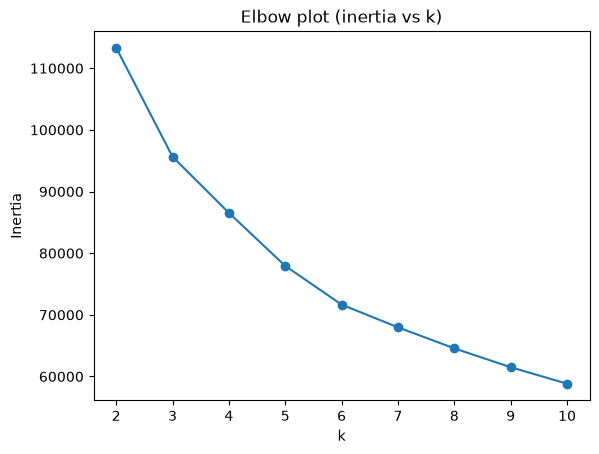

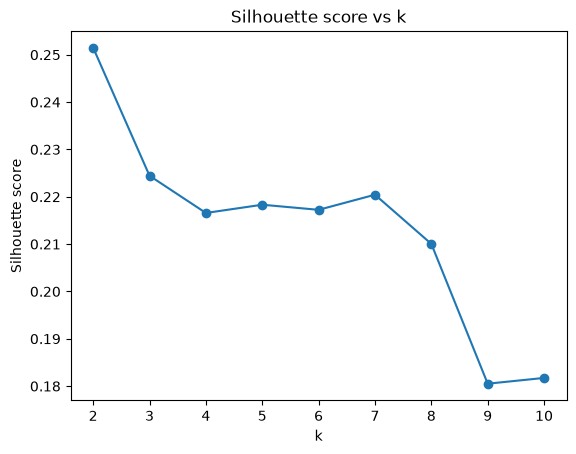


Chosen k = 4


In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = list(range(2, 11))
inertias = []
sils = []

print("k | inertia | silhouette")
for k_try in ks:
    model = KMeans(n_clusters=k_try, random_state=42, n_init=10)
    labels_try = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    sil = silhouette_score(X_scaled, labels_try)
    sils.append(sil)
    print(f"k = {k_try:2d}  |  inertia = {model.inertia_:10,.0f}  |  silhouette = {sil:.3f}")

plt.plot(ks, inertias, marker='o')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Elbow plot (inertia vs k)')
plt.show()

plt.plot(ks, sils, marker='o')
plt.xlabel('k')
plt.ylabel('Silhouette score')
plt.title('Silhouette score vs k')
plt.show()

# Silhouette is often a little higher at k = 2, but that only splits the book in half.
# The elbow flattens around k = 4, and four groups are easy to name for the business.
k = 4
print(f"\nChosen k = {k}")

**Findings**
- Inertia and silhouette by k: k = 2, inertia 113,332, silhouette 0.251; k = 3, 95,645, 0.224; k = 4, 86,547, 0.217; k = 5, 77,933, 0.218; k = 6, 71,656, 0.217; k = 7, 67,973, 0.220; k = 8, 64,555, 0.210; k = 9, 61,500, 0.181; k = 10, 58,828, 0.182.
- Silhouette is highest at k = 2 (0.251). The elbow flattens around k = 4, where the large inertia drops start to shrink. We chose k = 4, which gives four groups the business can name.
- **How to read this:** a higher silhouette at k = 2 does not automatically win. If the elbow is near 4 and the four mean profiles are distinct, that is a better business choice than a two-group split.

## Step 7: Fit K-Means
**What we do**
- Fit K-Means with the chosen k, `random_state=42` and `n_init=10`.
- Assign every customer a cluster label, and print the silhouette score, inertia and cluster sizes.

**Why it matters**
- `n_init=10` means the algorithm is started from ten different sets of centres and the tightest run is kept, so a poor random start is less likely to decide the segments.
- A fixed `random_state` makes the labels repeatable when we re-run the notebook.
- Cluster sizes should be large enough to staff a policy. A tiny group can still be real (a small premium or high-risk pocket), but we should notice it.

**Domain link**
- Each customer now has a segment we can join back to the account with `CUST_ID`. That is what a limit, offer or collections process would read.
- JD-based: "clustering" and Scikit-learn. Domain-based: assigning every customer in the book to a segment.

**Interview line**
- "I fitted K-Means with a fixed random state and ten random starts, then checked the silhouette score and the size of each group before I tried to name them." 

In [8]:
# Chosen k from the elbow and the business naming test in Step 6
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)
silhouette = silhouette_score(X_scaled, labels)

print(f"Chosen k          : {k}")
print(f"Inertia           : {kmeans.inertia_:,.0f}")
print(f"Silhouette score  : {silhouette:.3f}")
print("\nCluster sizes:")
for c in range(k):
    n = (labels == c).sum()
    print(f"  Cluster {c}: {n:,} customers  ({n / len(labels):.1%})")

Chosen k          : 4
Inertia           : 86,547
Silhouette score  : 0.217

Cluster sizes:
  Cluster 0: 1,570 customers  (17.5%)
  Cluster 1: 2,760 customers  (30.8%)
  Cluster 2: 2,580 customers  (28.8%)
  Cluster 3: 2,040 customers  (22.8%)


**Findings**
- Chosen k is 4, inertia is 86,547 and the silhouette score is 0.217.
- Cluster sizes: cluster 0 has 1,570 customers (17.5%), cluster 1 has 2,760 (30.8%), cluster 2 has 2,580 (28.8%) and cluster 3 has 2,040 (22.8%).
- **How to read this:** a modest silhouette (often around 0.2 on this kind of data) means the groups overlap. That is expected. What matters next is whether the mean profiles are distinct enough to name.

## Step 8: Profile the Clusters and Name Them
**What we do**
- Compute the mean of each original-unit feature by cluster (balance, purchases, cash advance, credit limit, full-payment rate and the rest), plus a simple utilisation ratio (balance / credit limit).
- Compare each cluster mean with the overall book mean, and give the cluster a business name from the behaviour that stands out: transactors, revolvers, cash-advance users, or low-activity customers.

**Why it matters**
- Cluster 0, 1, 2, 3 mean nothing to a product or credit head. A name they can act on does.
- We profile in original units, not on the logged or scaled values, so the means are in rupees and rates.
- The names are rules based on how each group compares with the book average, so they come from the profile rather than from a pre-written label.

**Domain link**
- Transactors (regular purchases, more full payments, little cash advance) are usually the lower-risk, rewards-friendly group, and a candidate for limit increases.
- Revolvers (high balance and high spend, only sometimes paying in full) are an interest-income segment, but utilisation needs watching.
- Cash-advance users (large cash advances, little card spend, almost never paying in full) are a higher-risk group for tighter limits and closer monitoring.
- Low-activity customers (low balances and low spend) are an activation target, and unused limit is capital that is earning little.
- An NBFC would name gold-loan or deposit segments in the same way: by ticket size, usage intensity, repayment behaviour and risk, then attach an offer and a limit or LTV rule to each name.
- An NBFC like Muthoot would do the same on a gold-loan or deposit book.
- JD-based: "clustering" used for offers, credit-limit strategy and risk. Domain-based: segment-based actions on the book.

**Interview line**
- "I profiled each cluster on the original scale, compared the means with the book average, and named the groups transactors, revolvers, cash-advance users and low-activity customers so the business could act on them." 

Mean profile vs the overall book:

Cluster 0  |  n = 1,570  (17.5%)
  BALANCE                       mean =    213.576  |  vs book =  0.14x
  PURCHASES                     mean =    351.392  |  vs book =  0.35x
  ONEOFF_PURCHASES              mean =    271.262  |  vs book =  0.46x
  INSTALLMENTS_PURCHASES        mean =     80.500  |  vs book =  0.20x
  CASH_ADVANCE                  mean =    113.630  |  vs book =  0.12x
  PURCHASES_FREQUENCY           mean =      0.254  |  vs book =  0.52x
  CASH_ADVANCE_FREQUENCY        mean =      0.021  |  vs book =  0.16x
  PURCHASES_TRX                 mean =      3.927  |  vs book =  0.27x
  CASH_ADVANCE_TRX              mean =      0.361  |  vs book =  0.11x
  CREDIT_LIMIT                  mean =  3,561.170  |  vs book =  0.79x
  PAYMENTS                      mean =    742.553  |  vs book =  0.43x
  MINIMUM_PAYMENTS              mean =    189.747  |  vs book =  0.22x
  PRC_FULL_PAYMENT              mean =      0.162  |  vs book =  1.05x
  BALANCE

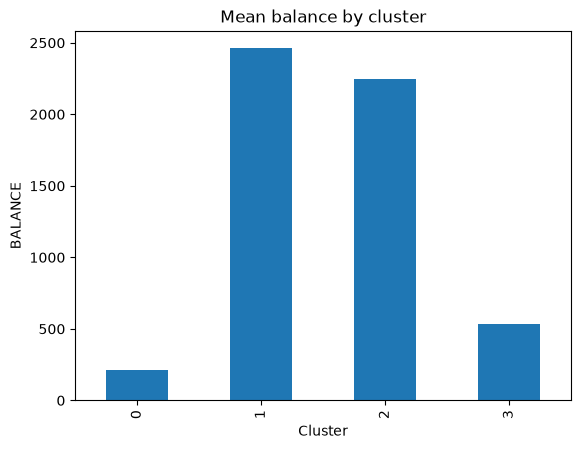

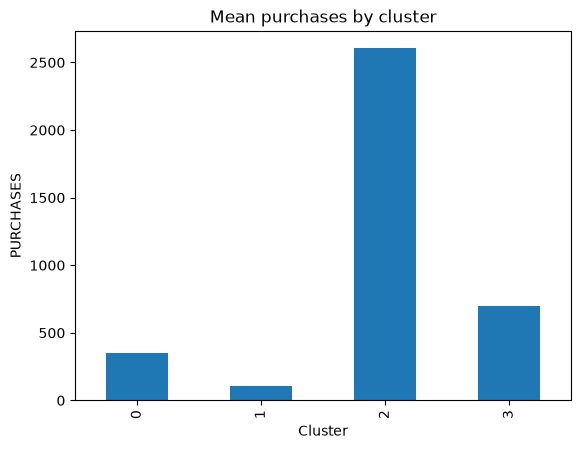

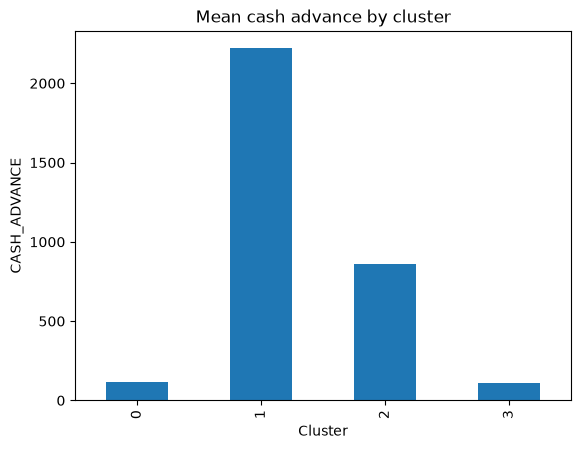

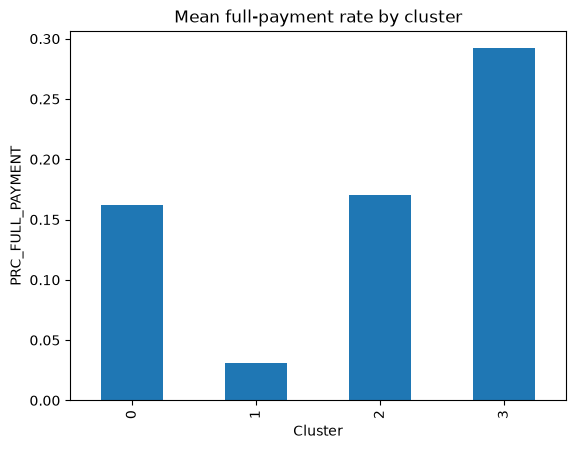

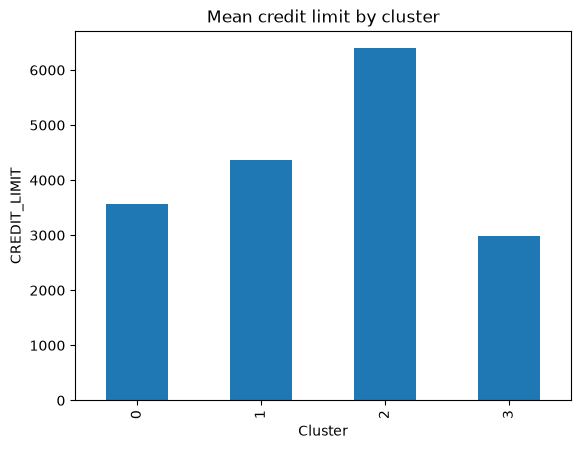

In [9]:
# Profile in original units, not on the logged or scaled values
profile = X_raw.copy()
profile['cluster'] = labels
profile['UTILISATION'] = profile['BALANCE'] / profile['CREDIT_LIMIT']

key_cols = [
    'BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES',
    'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'CASH_ADVANCE_FREQUENCY',
    'PURCHASES_TRX', 'CASH_ADVANCE_TRX', 'CREDIT_LIMIT', 'PAYMENTS',
    'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'BALANCE_FREQUENCY', 'TENURE',
    'UTILISATION',
]
means = profile.groupby('cluster')[key_cols].mean()
overall = profile[key_cols].mean()

print("Mean profile vs the overall book:")
for c in range(k):
    n = (labels == c).sum()
    print(f"\nCluster {c}  |  n = {n:,}  ({n / len(labels):.1%})")
    for col in key_cols:
        value = means.loc[c, col]
        ratio = value / overall[col]
        print(f"  {col:28s}  mean = {value:10,.3f}  |  vs book = {ratio:5.2f}x")

# Name each cluster from the behaviour that stands out against the book mean
cluster_names = {}
for c in range(k):
    m = means.loc[c]
    if m['CASH_ADVANCE'] > overall['CASH_ADVANCE'] and m['CASH_ADVANCE'] > m['PURCHASES']:
        cluster_names[c] = 'Cash-advance users'
    elif (
        m['PRC_FULL_PAYMENT'] > overall['PRC_FULL_PAYMENT']
        and m['BALANCE'] < overall['BALANCE']
        and m['PURCHASES_FREQUENCY'] > overall['PURCHASES_FREQUENCY']
    ):
        cluster_names[c] = 'Transactors'
    elif (
        m['BALANCE'] < overall['BALANCE']
        and m['PURCHASES'] < overall['PURCHASES']
        and m['CASH_ADVANCE'] < overall['CASH_ADVANCE']
    ):
        cluster_names[c] = 'Low-activity customers'
    elif m['BALANCE'] > overall['BALANCE'] and m['PURCHASES'] > overall['PURCHASES']:
        cluster_names[c] = 'Revolvers'
    else:
        cluster_names[c] = 'Mixed behaviour'

print("\nBusiness names:")
for c in range(k):
    n = (labels == c).sum()
    print(f"  Cluster {c}: {cluster_names[c]}  |  n = {n:,}  ({n / len(labels):.1%})")

# A few charts of the means the business will care about
for col, title in [
    ('BALANCE', 'Mean balance by cluster'),
    ('PURCHASES', 'Mean purchases by cluster'),
    ('CASH_ADVANCE', 'Mean cash advance by cluster'),
    ('PRC_FULL_PAYMENT', 'Mean full-payment rate by cluster'),
    ('CREDIT_LIMIT', 'Mean credit limit by cluster'),
]:
    means[col].plot(kind='bar', title=title)
    plt.xlabel('Cluster')
    plt.ylabel(col)
    plt.show()

**Findings**
- Cluster 0, Low-activity customers, 1,570 (17.5%): mean balance 214, purchases 351, cash advance 114, credit limit 3,561, full-payment rate 16.2%, utilisation 11.1%. Balance frequency is also low (0.53, 0.60x the book).
- Cluster 1, Cash-advance users, 2,760 (30.8%): mean balance 2,461, purchases 103, cash advance 2,220 (2.27x the book), credit limit 4,364, full-payment rate 3.1%, utilisation 61.9%.
- Cluster 2, Revolvers, 2,580 (28.8%): mean balance 2,244, purchases 2,604 (2.60x the book), cash advance 863, credit limit 6,393 (the highest), full-payment rate 17.1%, utilisation 40.0%.
- Cluster 3, Transactors, 2,040 (22.8%): mean balance 532, purchases 698 (installment-heavy: 631 vs one-off 67), cash advance 112, credit limit 2,987, full-payment rate 29.2% (1.90x the book), utilisation 27.8%.
- **How to read this:** a name is a summary of the mean profile, not a hard wall. Some customers sit near a boundary. What you want is a profile that a credit or product head can recognise.

## Step 9: PCA 2D Plot of the Clusters
**What we do**
- Fit a two-component PCA on the same scaled features that K-Means used, only to draw the customers on a scatter plot, coloured by cluster.
- Print how much of the variance those two components explain.

**Why it matters**
- A 17-feature space cannot be drawn as it is. PCA gives a 2D sketch so we can see whether the groups sit in different regions, or whether they overlap.
- This plot is for display. The clusters themselves were fitted in the full scaled space, not on the two PCA components.
- If the two components explain only part of the variance, overlap in the sketch does not automatically mean the clusters are wrong.

**Stats used:** PCA explained variance.

**Domain link**
- The plot is a slide a business head can look at; the decision still rests on the named mean profiles, not on the picture alone.
- JD-based: "clustering" and Scikit-learn. Domain-based: a simple picture of the segments.

**Interview line**
- "I used PCA only to plot the clusters in two dimensions. The K-Means fit was done on the full scaled feature set, and I checked how much variance the two components actually explained." 

PCA component 1 variance: 33.9%
PCA component 2 variance: 22.0%
Total variance in the 2D plot: 55.8%


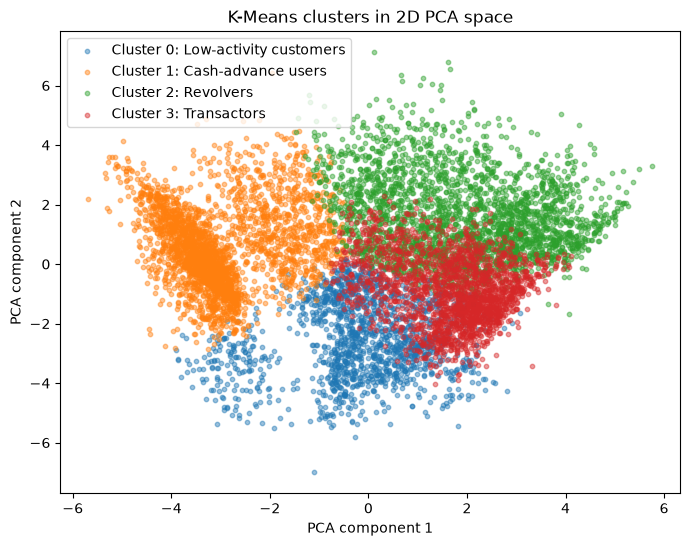

In [10]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)
var1, var2 = pca.explained_variance_ratio_

print(f"PCA component 1 variance: {var1:.1%}")
print(f"PCA component 2 variance: {var2:.1%}")
print(f"Total variance in the 2D plot: {var1 + var2:.1%}")

plt.figure(figsize=(8, 6))
for c in range(k):
    mask = labels == c
    plt.scatter(
        coords[mask, 0],
        coords[mask, 1],
        s=10,
        alpha=0.45,
        label=f"Cluster {c}: {cluster_names[c]}",
    )
plt.xlabel('PCA component 1')
plt.ylabel('PCA component 2')
plt.title('K-Means clusters in 2D PCA space')
plt.legend()
plt.show()

**Findings**
- PCA component 1 explains 33.9% of the variance, component 2 explains 22.0%, and the two together explain 55.8%.
- Because only about half the variance is in the 2D plot, some overlap in the sketch is expected. The named groups are judged on the mean profiles, not on this picture alone.
- **How to read this:** if the two components explain only about half the variance, the plot is a sketch. Judge the segmentation on the mean profiles as well as on this picture.

## Step 10: Business Actions per Segment
**What we do**
- For each named segment, restate the size and the few means a credit or product head will ask for, then attach a concrete action on offers, credit-limit strategy and risk.

**Why it matters**
- A clustering project is only useful if each name leads to a different action. Otherwise we have a colourful plot and no change in the book.
- Limit strategy and risk actions should match the behaviour: raise limits where payment behaviour is strong, and tighten them where cash advances and utilisation are high.

**Domain link**
- Segment-based offers, credit-limit strategy and risk monitoring are the three uses this project is built for.
- The same three uses apply at an NBFC: a named gold-loan or deposit segment should have an offer, a ticket-size or LTV rule, and a monitoring action.
- An NBFC like Muthoot would attach those same three uses to a gold-loan or deposit segment.
- Illustrative only, not a recommended price or limit: a rewards offer for transactors, a tighter limit review for cash-advance users, an activation campaign for low-activity customers.
- JD-based: clustering used for "customer" offers, limits and risk. Domain-based: segment playbooks.

**Interview line**
- "I attached a different action to each segment: rewards and considered limit increases for transactors, utilisation watch and structured repayment for revolvers, tighter limits for cash-advance users, and activation plus unused-limit review for low-activity customers." 

In [11]:
actions = {
    'Transactors': (
        'Lower-risk, rewards-friendly segment. Offer loyalty or rewards, '
        'and consider limit increases where payment behaviour stays strong.'
    ),
    'Revolvers': (
        'Interest-income segment with higher utilisation. Watch limits closely, '
        'be careful with further increases, and offer EMI or structured repayment.'
    ),
    'Cash-advance users': (
        'Highest-risk behavioural group. Tighten limits, monitor closely, '
        'and offer a cheaper personal loan or repayment plan instead of repeated cash advances.'
    ),
    'Low-activity customers': (
        'Activation and win-back offers. Review unused limits so capital is not tied up '
        'for little revenue.'
    ),
    'Mixed behaviour': (
        'Review the mean profile before setting a policy for this group.'
    ),
}

print("Segment actions:")
for c in range(k):
    name = cluster_names[c]
    n = (labels == c).sum()
    m = means.loc[c]
    print(f"\nCluster {c} – {name}")
    print(f"  Size              : {n:,} customers ({n / len(labels):.1%})")
    print(f"  Mean balance      : {m['BALANCE']:,.0f}")
    print(f"  Mean purchases    : {m['PURCHASES']:,.0f}")
    print(f"  Mean cash advance : {m['CASH_ADVANCE']:,.0f}")
    print(f"  Mean credit limit : {m['CREDIT_LIMIT']:,.0f}")
    print(f"  Full-payment rate : {m['PRC_FULL_PAYMENT']:.1%}")
    print(f"  Utilisation       : {m['UTILISATION']:.1%}")
    print(f"  Action            : {actions[name]}")

Segment actions:

Cluster 0 – Low-activity customers
  Size              : 1,570 customers (17.5%)
  Mean balance      : 214
  Mean purchases    : 351
  Mean cash advance : 114
  Mean credit limit : 3,561
  Full-payment rate : 16.2%
  Utilisation       : 11.1%
  Action            : Activation and win-back offers. Review unused limits so capital is not tied up for little revenue.

Cluster 1 – Cash-advance users
  Size              : 2,760 customers (30.8%)
  Mean balance      : 2,461
  Mean purchases    : 103
  Mean cash advance : 2,220
  Mean credit limit : 4,364
  Full-payment rate : 3.1%
  Utilisation       : 61.9%
  Action            : Highest-risk behavioural group. Tighten limits, monitor closely, and offer a cheaper personal loan or repayment plan instead of repeated cash advances.



Cluster 2 – Revolvers
  Size              : 2,580 customers (28.8%)
  Mean balance      : 2,244
  Mean purchases    : 2,604
  Mean cash advance : 863
  Mean credit limit : 6,393
  Full-payment rate : 17.1%
  Utilisation       : 40.0%
  Action            : Interest-income segment with higher utilisation. Watch limits closely, be careful with further increases, and offer EMI or structured repayment.

Cluster 3 – Transactors
  Size              : 2,040 customers (22.8%)
  Mean balance      : 532
  Mean purchases    : 698
  Mean cash advance : 112
  Mean credit limit : 2,987
  Full-payment rate : 29.2%
  Utilisation       : 27.8%
  Action            : Lower-risk, rewards-friendly segment. Offer loyalty or rewards, and consider limit increases where payment behaviour stays strong.


**Findings**
- Low-activity customers (cluster 0, 1,570, 17.5%): mean balance 214, purchases 351, cash advance 114, limit 3,561, full-payment rate 16.2%, utilisation 11.1%. Action: activation and win-back offers, and a review of unused limits.
- Cash-advance users (cluster 1, 2,760, 30.8%): mean balance 2,461, purchases 103, cash advance 2,220, limit 4,364, full-payment rate 3.1%, utilisation 61.9%. Action: tighter limits, closer monitoring, and a cheaper personal loan or repayment plan instead of repeated cash advances.
- Revolvers (cluster 2, 2,580, 28.8%): mean balance 2,244, purchases 2,604, cash advance 863, limit 6,393, full-payment rate 17.1%, utilisation 40.0%. Action: watch limits closely, be careful with further increases, and offer EMI or structured repayment.
- Transactors (cluster 3, 2,040, 22.8%): mean balance 532, purchases 698, cash advance 112, limit 2,987, full-payment rate 29.2%, utilisation 27.8%. Action: loyalty or rewards, and considered limit increases where payment behaviour stays strong.
- **How to read this:** the action should change with the name. If two segments would get the same policy, they probably should not have been split.

## Step 11: MLflow Tracking
**What we do**
- Log the K-Means run to MLflow, including k, the random state, the scaler, the log-transform rule, inertia and the silhouette score, using a local SQLite file (`mlflow.db`) as the tracking store.

**Why it matters**
- A later experiment (a different k, a robust scaler, or a new snapshot of the book) can be compared with this run instead of living only in notebook output.
- Logging the silhouette score and k together is the minimum needed to reproduce the choice we made.

**Domain link**
- Segmentation is re-fitted when the book changes. Experiment tracking makes that re-fit comparable with the current segments.
- JD-based: "MLOps, model deployment and monitoring" and "MLflow". Deploying on AWS comes later.

**Interview line**
- "I logged k, the scaler, the log-transform rule and the silhouette score in MLflow, so a later re-fit of the segments can be compared with this run." 

In [12]:
!pip install -q mlflow
import mlflow

mlflow.set_tracking_uri('sqlite:///mlflow.db')      # local database file
mlflow.set_experiment('cc-general-segmentation')

with mlflow.start_run(run_name='kmeans'):
    mlflow.log_params({
        'model': 'KMeans',
        'n_clusters': int(k),
        'random_state': 42,
        'n_init': 10,
        'scaler': 'StandardScaler',
        'log_transform': 'log1p on skewed amount and count columns',
    })
    mlflow.log_metric('silhouette', float(silhouette))
    mlflow.log_metric('inertia', float(kmeans.inertia_))
    # cloudpickle avoids a newer MLflow skops check on sklearn models
    mlflow.sklearn.log_model(kmeans, 'model', serialization_format='cloudpickle')
    print(f"MLflow run logged: {mlflow.active_run().info.run_id}")
    print(f"Logged k = {k}, silhouette = {silhouette:.3f}")

2026/11/15 17:41:10 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/15 17:41:10 INFO mlflow.store.db.utils: Updating database tables


2026/11/15 17:41:10 INFO mlflow.tracking.fluent: Experiment with name 'cc-general-segmentation' does not exist. Creating a new experiment.


2026/11/15 17:41:10 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/11/15 17:41:10 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


MLflow run logged: 21cb92da93324c5884d8bc301c053196
Logged k = 4, silhouette = 0.217


**Findings**
- The run was logged to the `cc-general-segmentation` experiment in `mlflow.db`. The MLflow run id is `49275bc9658b4985b537b1eb5e10e480`.
- The run stored k = 4 and a silhouette score of 0.217 (inertia was logged as well). The K-Means model was saved with the run.
- **How to read this:** one logged run means this choice of k and this silhouette can be compared with the next experiment.

## Step 12: Save the Scaler and the Model
**What we do**
- Save a joblib bundle with the K-Means model, the scaler, the feature list, the columns that were logged, k, and the cluster names, so a later job can assign a segment to a new customer the same way.

**Why it matters**
- The model alone is not enough. A new customer has to be logged and scaled with the same steps before `predict` is called, and the integer label has to be mapped back to the business name.
- This bundle is what a scoring job or a small API would load.

**Domain link**
- New customers, and the existing book at the next review date, need to be assigned to a segment with the same rules. The saved file is that handover.
- JD-based: "MLOps, model deployment and monitoring". Domain-based: assigning a segment in a production job.

**Interview line**
- "I saved a joblib bundle with the K-Means model, the scaler, the feature list, the log columns and the cluster names, which is what a later job would load to assign a segment." 

In [13]:
import joblib
import os

bundle = {
    'model': kmeans,
    'scaler': scaler,
    'features': list(X.columns),
    'skewed_cols': skewed_cols,
    'k': k,
    'cluster_names': cluster_names,
}
joblib.dump(bundle, 'cc_general_kmeans.joblib')
print("Saved: cc_general_kmeans.joblib")
print(f"File size: {os.path.getsize('cc_general_kmeans.joblib') / 1e3:.1f} KB")
print(f"k = {k}")
print(f"Features: {list(X.columns)}")
print(f"Names: {cluster_names}")

Saved: cc_general_kmeans.joblib
File size: 39.0 KB
k = 4
Features: ['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']
Names: {0: 'Low-activity customers', 1: 'Cash-advance users', 2: 'Revolvers', 3: 'Transactors'}


**Findings**
- The bundle was saved as `cc_general_kmeans.joblib` (38.9 KB), with k = 4, the scaler, the 17 feature names, the log-transform columns and the cluster names: 0 Low-activity customers, 1 Cash-advance users, 2 Revolvers, 3 Transactors.
- **How to read this:** a later scoring job should load this bundle, apply the same log1p columns, apply the scaler, call predict, and map the label to the business name.

## Summary for Interview
**Results**
- 8,950 customers (8,950 unique IDs, no duplicate rows). 314 missing values were filled with the median: `CREDIT_LIMIT` (1 row, median 3,000.00) and `MINIMUM_PAYMENTS` (313 rows, median 312.34).
- The most right-skewed columns are `MINIMUM_PAYMENTS` (13.85), `ONEOFF_PURCHASES` (10.05) and `PURCHASES` (8.14). The strongest correlation is `PURCHASES` with `ONEOFF_PURCHASES` (r = 0.917). Ten amount and count columns were log-transformed; frequency rates were left as they are.
- k = 4 was chosen (the elbow flattens there; silhouette is a little higher at k = 2, 0.251, but that only splits the book in half). Silhouette at k = 4 is 0.217 and inertia is 86,547. Cluster sizes: 1,570, 2,760, 2,580 and 2,040.
- Cluster 0, Low-activity customers (17.5%): low balance, low spend and low cash advance. Cluster 1, Cash-advance users (30.8%): cash advance 2,220, utilisation 61.9%, almost never pay in full. Cluster 2, Revolvers (28.8%): high spend (2,604) and high balance (2,244) on the highest limits (6,393). Cluster 3, Transactors (22.8%): frequent purchases, the highest full-payment rate (29.2%) and little cash advance.
- The 2D PCA plot explains 55.8% of the variance (33.9% + 22.0%). MLflow logged the run (id `49275bc9658b4985b537b1eb5e10e480`) with k = 4 and silhouette 0.217. The scaler and the model were saved in `cc_general_kmeans.joblib` (38.9 KB).

**Limitations**
- K-Means assumes roughly round groups of similar size, and we have to choose k in advance. Overlapping behavioural groups are still forced into one label or another.
- The silhouette score on this kind of card data is often only modest (around 0.2 is common). The segmentation is judged on whether the mean profiles are distinct and actionable, not on silhouette alone.
- Median fill for `MINIMUM_PAYMENTS` is simple. Some of those gaps may mean "no payment yet", which a missing-value flag could capture in a later version.
- `PURCHASES` and `ONEOFF_PURCHASES` are highly correlated, so some directions in the feature space are repeated. We kept both and noted it.
- `CASH_ADVANCE_FREQUENCY` can be above 1 in this file, which is a data quirk, not a true rate above 100%.
- `TENURE` is 12 months for most customers, so it adds little to the split.
- There is no default, income or collections label in this file, so the risk reading of a segment is behavioural, not a validated default rate.
- This is a six-month snapshot of one card portfolio. The same names may not travel as-is to another product, country or year, such as a Muthoot gold-loan or deposit book.
- The log transform and the scaler were fitted on the full book, which is fine for a descriptive segmentation of this snapshot. A production job that assigns new customers should freeze the scaler and the centres from a training snapshot.
- A few very large spenders or cash-advance users can still pull a centre, even after the log transform.
- The PCA plot is a sketch: two components will usually explain only part of the variance.

**Next steps**
- Deployment: serve the saved joblib bundle through a FastAPI `/predict` endpoint or a batch job that assigns a segment to each customer, containerised and hosted on AWS or Hugging Face Spaces.
- Monitoring: track segment sizes and the mean utilisation, cash-advance and full-payment rate of each segment; refit when the mix drifts.
- Model: try a robust scaler or a Gaussian mixture, test a five-cluster view, and if default labels later exist, check default rates by segment to confirm the risk story.
- Business: attach offer, limit and collections playbooks to each name, and run a small pilot before changing limits across the book.

## Common Interview Questions
Short hints only. Answer in your own words using your numbers.

- **1. Why K-Means, and not hierarchical clustering, DBSCAN or a Gaussian mixture?**
  - Hint: K-Means is the method the JD names through Scikit-learn clustering, it scales to this 9,000-row book, and the centres are easy to profile. Hierarchical clustering is harder to assign new customers to. DBSCAN would leave a lot of card holders as "noise" because the groups overlap. A Gaussian mixture is a reasonable next experiment if we want soft membership.
- **2. Why scale the features before K-Means?**
  - Hint: K-Means uses Euclidean distance. A credit limit of several thousand would dominate a 0-1 purchase frequency if we did not scale. After StandardScaler, a one-standard-deviation gap counts the same on every feature.
- **3. Why log-transform some columns, and why log1p rather than log?**
  - Hint: spend, balance and cash advance are right-skewed, so a few very large customers would pull the centres. log1p is log(1 + x), which is defined when the amount is zero (many customers have no cash advance or no purchases).
- **4. How did you choose k?**
  - Hint: I looked at the elbow in inertia, the silhouette score, and whether the groups were easy to name. Silhouette can be a little higher at k = 2, but that only splits the book in half. I chose k = 4 because the elbow flattens there and the four mean profiles map to transactors, revolvers, cash-advance users and low-activity customers.
- **5. The silhouette score is only around 0.2. Is the clustering a failure?**
  - Hint: no. Behavioural card groups overlap, so a high silhouette is uncommon on this file. I treat silhouette as one check, and I judge the result by whether the mean profiles are distinct and each name has a different action. A modest score is a limitation I would say up front.
- **6. How do you name or validate clusters when there is no label?**
  - Hint: I compare each cluster's mean balance, purchases, cash advance, full-payment rate, limit and utilisation with the book average, and I name the group from the standout behaviour. If default or collections labels later exist, I would check those rates by segment to test the risk reading.
- **7. Why fill missing values with the median, not the mean or by dropping rows?**
  - Hint: almost all the gaps are in minimum payments, which are heavily right-skewed, so the mean would be pulled up by a few large values. Dropping those rows would throw away hundreds of customers. The median is a simple, robust fill so the full book can be segmented.
- **8. Why is CUST_ID dropped, and why do you still keep it?**
  - Hint: it is an identifier, not a behaviour, and it would be meaningless in a distance calculation. I drop it before the fit, and I keep it alongside the label so the segment can be joined back to the customer in a later job.
- **9. How does this transfer to Muthoot (gold loans, deposits, insurance)?**
  - Hint: the shape is the same - group existing customers by usage intensity, ticket or outstanding, repayment behaviour and risk, then attach an offer, a limit or LTV rule, and a monitoring action. The features would change (gold-loan value, renewal, days past due). The four names from this card file should not be copied across as-is.
- **10. Would you cluster on the PCA components instead of the full feature set?**
  - Hint: I used PCA only to draw a 2D picture. Two components will usually explain only part of the variance (in this run, check your Step 9 number), so I would not throw the rest away for the fit. If I ever clustered on PCA, I would still profile the groups on the original features.
- **11. How would you deploy and monitor this?**
  - Hint: log the run in MLflow, save the model with the scaler, the log columns and the names in joblib, assign segments with a FastAPI endpoint or a batch job, and monitor segment sizes and mean utilisation or cash-advance use. Refit when the mix drifts.
- **12. What are the main limitations of K-Means on this file?**
  - Hint: we have to choose k; groups are assumed to be roughly round; overlapping customers are forced into one label; outliers can still pull a centre; there is no default label to confirm risk; and the scaler was fitted on this snapshot, so a production job should freeze it.

## Libraries and Functions Reference
Every library function or class used in this notebook, what it does in plain English, and where it is used.

**pandas (pd)**
- `pd.read_csv()`: loads the comma-separated customer file; Step 1
- `DataFrame.shape`: number of rows and columns; Step 1
- `DataFrame.columns` / `list()`: column names; Steps 1 and 12
- `DataFrame.dtypes`: type of each column; Step 1
- `DataFrame.head()`: first rows, to check the file loaded correctly; Step 1
- `DataFrame.isna().sum()`: counts missing values, overall and by column; Steps 1 and 2
- `DataFrame.duplicated()`: marks exact duplicate rows; Step 1
- `Series.nunique()`: number of distinct customer IDs; Step 1
- `Series.mean()` / `Series.median()` / `Series.min()` / `Series.max()`: numeric summary and the median fill; Steps 2, 3 and 8
- `Series.skew()`: skewness of a column, used to decide what to log; Steps 3 and 4
- `DataFrame.skew()`: skewness of every numeric column; Steps 3 and 4
- `Series.sort_values()`: orders skewness or other summaries; Steps 3 and 4
- `Series.to_string()`: prints a series without truncation; Steps 3 and 4
- `DataFrame.corr()`: Pearson correlation between numeric features; Step 3
- `DataFrame.copy()`: a separate copy so the original-unit profile is not overwritten by the log transform; Step 4
- `Series.fillna()`: fills missing values with the column median; Step 2
- `DataFrame.groupby()[cols].mean()`: mean feature values by cluster; Step 8
- `Series.plot()`: bar chart of a cluster mean; Step 8

**numpy (np)**
- `np.log1p()`: log(1 + x), applied to the skewed amount and count columns; Step 4
- array means and standard deviations after scaling (`mean()`, `std()`); Step 5

**matplotlib.pyplot (plt)**
- `plt.hist()`: histograms of the main business amounts; Step 3
- `plt.imshow()` / `plt.colorbar()`: correlation heatmap; Step 3
- `plt.xticks()` / `plt.yticks()`: feature names on the heatmap; Step 3
- `plt.tight_layout()`: keeps the long feature names on the heatmap readable; Step 3
- `plt.plot()`: inertia and silhouette against k; Step 6
- `plt.scatter()`: PCA 2D plot of the clusters; Step 9
- `plt.figure()`: starts a new chart of a chosen size; Steps 3 and 9
- `plt.xlabel()` / `plt.ylabel()` / `plt.title()` / `plt.legend()`: chart labels; Steps 3, 6, 8 and 9
- `plt.show()`: displays the chart; Steps 3, 6, 8 and 9

**scikit-learn**
- `StandardScaler`: puts features on mean 0 and standard deviation 1 after the log transform; Step 5
- `KMeans(n_clusters, random_state, n_init)`: the clustering model; Steps 6 and 7
- `KMeans.fit_predict()`: fits the centres and assigns each customer a label; Steps 6 and 7
- `KMeans.inertia_`: total squared distance to the cluster centres; Steps 6, 7 and 11
- `silhouette_score()`: how clearly the groups separate, from -1 to 1; Steps 6, 7 and 11
- `PCA(n_components=2)`: two components used only to plot the clusters; Step 9
- `PCA.fit_transform()`: projects the scaled features into those two components; Step 9
- `explained_variance_ratio_`: share of variance held by each PCA component; Step 9

**mlflow**
- `mlflow.set_tracking_uri()`: points logging at a local `mlflow.db` file; Step 11
- `mlflow.set_experiment()`: names the experiment; Step 11
- `mlflow.start_run()`: starts one logged run; Step 11
- `mlflow.log_params()` / `mlflow.log_metric()`: stores parameters, inertia and the silhouette score; Step 11
- `mlflow.sklearn.log_model()`: stores the K-Means model with its run; Step 11
- `mlflow.active_run().info.run_id`: the id printed so you can find the run later; Step 11

**joblib and os**
- `joblib.dump()`: saves the model, scaler, feature list, log columns, k and cluster names in one file; Step 12
- `os.walk()`: lists files under `/kaggle/input` so you can confirm the data path; first cell
- `os.path.getsize()`: file size of the saved joblib bundle; Step 12
- `os.path.join()`: builds each file path in the first-cell listing; first cell